In [2]:
from rdkit import Chem
from rdkit.Chem import AllChem
from rdkit.Chem import rdFMCS, rdRGroupDecomposition
from rdkit.Chem import PandasTools
import numpy as np
import useful_rdkit_utils as uru
import mols2grid
from rdkit.Chem.Draw import rdDepictor
from rdkit.Chem.Draw import rdMolDraw2D
import io
import base64
from IPython.display import HTML
import seaborn as sns
import matplotlib.pyplot as plt
import requests
import pandas as pd

# This is essential when rendering a Pandas dataframe with R-group results
PandasTools.RenderImagesInAllDataFrames(images=True)

In [3]:
url = "https://raw.githubusercontent.com/PatWalters/practical_cheminformatics_tutorials/main/patent/data/35A6EC1A3C9266A38807F72D62C1E3FBki.sdf"
r = requests.get(url)
filename = "/Users/zhangzhewen/Desktop/AIDD学习/US20240109915_BindingDB_2D.sdf"
with open(filename, "w") as ofs:
    ofs.write(r.text)
df = PandasTools.LoadSDF(filename)

In [4]:
df.columns

Index(['From', 'BindingDB Reactant_set_id', 'Ligand InChI', 'Ligand InChI Key',
       'BindingDB MonomerID', 'BindingDB Ligand Name', 'Target Name',
       'Target Source Organism According to Curator or DataSource', 'Ki (nM)',
       'IC50 (nM)', 'Kd (nM)', 'EC50 (nM)', 'kon (M-1-s-1)', 'koff (s-1)',
       'pH', 'Temp C', 'Curation/DataSource', 'Article DOI',
       'BindingDB Entry DOI', 'PMID', 'PubChem AID', 'Patent Number',
       'Authors', 'Institution', 'Link to Ligand in BindingDB',
       'Link to Ligand-Target Pair in BindingDB', 'Ligand HET ID in PDB',
       'PDB ID(s) for Ligand-Target Complex', 'PubChem CID', 'PubChem SID',
       'ChEBI ID of Ligand', 'ChEMBL ID of Ligand', 'DrugBank ID of Ligand',
       'IUPHAR_GRAC ID of Ligand', 'KEGG ID of Ligand', 'ZINC ID of Ligand',
       'Number of Protein Chains in Target (bigger than 1 implies a multichain complex)',
       'BindingDB Target Chain Sequence', 'PDB ID(s) of Target Chain',
       'UniProt (SwissProt) Recommen

In [5]:
activity_cols = ['Ki (nM)','IC50 (nM)', 'Kd (nM)', 'EC50 (nM)']

In [6]:
df[activity_cols].replace('', np.nan).count()

Ki (nM)        0
IC50 (nM)    102
Kd (nM)        0
EC50 (nM)      0
dtype: int64

In [7]:
df["IC50 (nM)"].values

<ArrowStringArray>
[' 0.900',  ' 1.30',  ' 1.30',  ' 1.50',  ' 1.80',  ' 2.20',  ' 2.40',
  ' 2.40',  ' 2.60',  ' 3.10',
 ...
  ' 45.5',  ' 46.5',  ' 65.4',  ' 85.9',  ' 92.6',   ' 109',   ' 115',
   ' 189', ' 10000', ' 10000']
Length: 102, dtype: str

In [8]:
df["IC50 (nM)"] = df["IC50 (nM)"].astype(float)

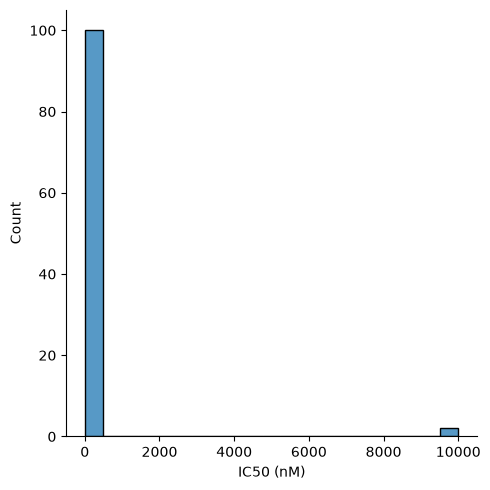

In [9]:
sns.displot(df["IC50 (nM)"]);

In [10]:
df['pIC50'] = -np.log10(df["IC50 (nM)"] * 1e-9)

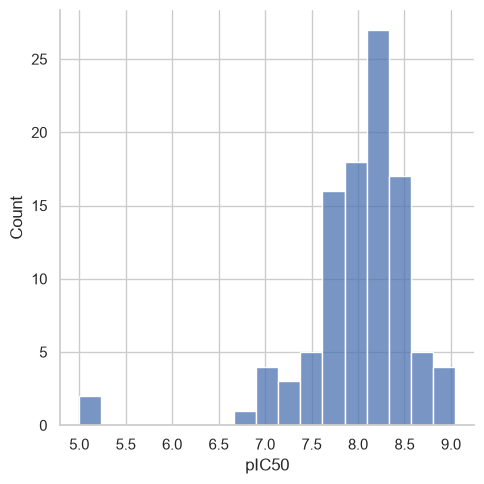

In [11]:
sns.set(rc={'figure.figsize': (10, 10)})
sns.set_style('whitegrid')
sns.displot(df.pIC50);

In [12]:
df['SMILES'] = df.ROMol.apply(Chem.MolToSmiles)
df['scaffold_smi'] = df.SMILES.apply(Chem.Scaffolds.MurckoScaffold.MurckoScaffoldSmiles)

,scaffold_smi,count,mol
0,O=C1CC2(CCN(C(=O)c3ccc4[nH]ncc4c3)CC2)Cc2scnc21,13,
1,O=C1CC2(CCN(C(=O)c3ccc4ncccc4c3)CC2)Cc2scnc21,13,
2,O=C1CC2(CCN(C(=O)c3ccc4[nH]ccc4c3)CC2)Cc2scnc21,9,
3,O=C1CC2(CCN(C(=O)c3ccc4ccccc4c3)CC2)Cc2scnc21,8,
4,O=C1CC2(CCN(C(=O)c3ccc4cc[nH]c4c3)CC2)Cc2scnc21,8,

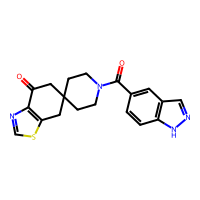
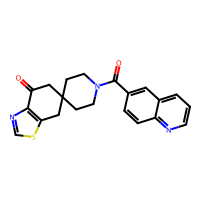
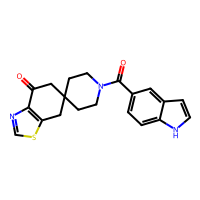
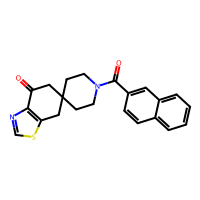
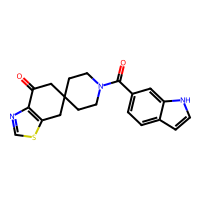

In [13]:
scaffold_df=uru.value_counts_df(df,"scaffold_smi")
scaffold_df["mol"]=scaffold_df.scaffold_smi.apply(Chem.MolFromSmiles)
[rdDepictor.Compute2DCoords(m) for m in scaffold_df.mol]
scaffold_df.head()

Text(0, 0.5, 'Number of Examples')

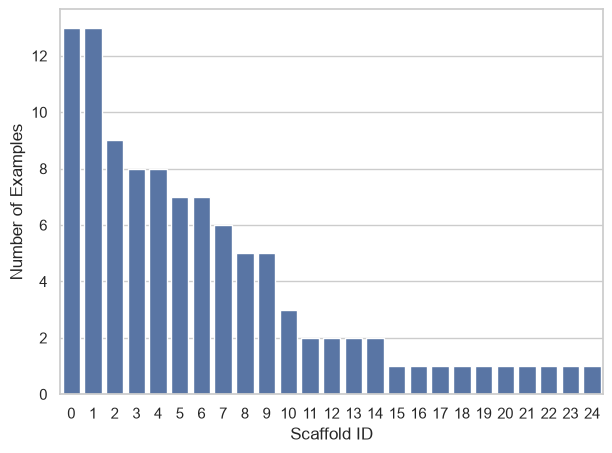

In [14]:
sns.set(rc={'figure.figsize': (7, 5)})
sns.set_style('whitegrid')
ax = sns.barplot(x=range(0,len(scaffold_df)),y=scaffold_df["count"].values)
ax.set_xlabel("Scaffold ID")
ax.set_ylabel("Number of Examples")

In [15]:
def boxplot_base64_image(dist: np.ndarray, x_lim: list[int] = [0, 10]) -> str:
    """
    Plot a distribution as a seaborn boxplot and save the resulting image as a base64 image.

    Parameters:
    dist (np.ndarray): The distribution data to plot.
    x_lim (list[int]): The x-axis limits for the boxplot.

    Returns:
    str: The base64 encoded image string.
    """
    sns.set(rc={'figure.figsize': (3, 1)})
    sns.set_style('whitegrid')
    ax = sns.boxplot(x=dist)
    ax.set_xlim(x_lim[0], x_lim[1])
    s = io.BytesIO()
    plt.savefig(s, format='png', bbox_inches="tight")
    plt.close()
    s = base64.b64encode(s.getvalue()).decode("utf-8").replace("\n", "")
    return '<img align="left" src="data:image/png;base64,%s">' % s


def mol_to_base64_image(mol: Chem.Mol) -> str:
    """
    Convert an RDKit molecule to a base64 encoded image string.

    Parameters:
    mol (Chem.Mol): The RDKit molecule to convert.

    Returns:
    str: The base64 encoded image string.
    """
    drawer = rdMolDraw2D.MolDraw2DCairo(300, 150)
    drawer.DrawMolecule(mol)
    drawer.FinishDrawing()
    text = drawer.GetDrawingText()
    im_text64 = base64.b64encode(text).decode('utf8')
    img_str = f"<img src='data:image/png;base64, {im_text64}'/>"
    return img_str


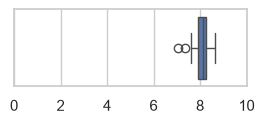
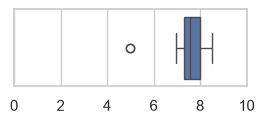
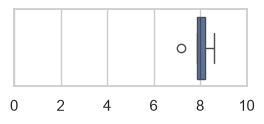
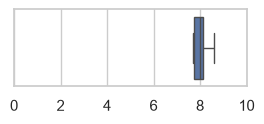
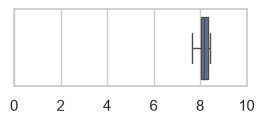
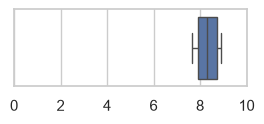
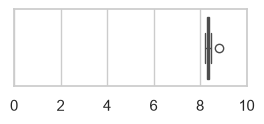
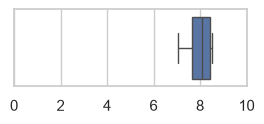
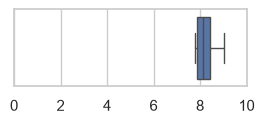
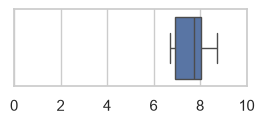

In [16]:
rows_to_display = 10
tmp_df = scaffold_df.head(rows_to_display).copy()
tmp_df['mol_img'] = tmp_df.mol.apply(mol_to_base64_image)
img_list = []
for smi in tmp_df.scaffold_smi:
    img_list.append(boxplot_base64_image(df.query("scaffold_smi == @smi").pIC50.values))
tmp_df['dist_img'] = img_list
HTML(tmp_df[['mol_img','count','dist_img']].to_html(escape=False))

In [17]:
scaffold_id = 1
scaffold_smi = scaffold_df.scaffold_smi.values[scaffold_id]
tmp_df = df.query("scaffold_smi == @scaffold_smi").copy()
tmp_df['mol'] = tmp_df.SMILES.apply(Chem.MolFromSmiles)
scaffold_mol = scaffold_df.mol.values[scaffold_id]
AllChem.Compute2DCoords(scaffold_mol)
[AllChem.GenerateDepictionMatching2DStructure(m,scaffold_mol) for m in tmp_df.mol]
mols2grid.display(tmp_df.sort_values("IC50 (nM)"),size=(175,175),subset=["img","IC50 (nM)"], mol_col="mol",
                  use_coords=True, prerender=True)

In [18]:
mcs_res = rdFMCS.FindMCS(df.ROMol.values)

In [19]:
mcs_res.smartsString

'[#6]12:[#6](-[#6]-[#6]3(-[#6]-[#6]-1)-[#6]-[#6]-[#7](-[#6]-[#6]-3)-[#6](-[#6]:[#6]:[#6]:,-[#6]:,-[#6]:,-[#6])=[#8]):[#16]:[#6](:[#7]:2)-[#6]-[#6]'

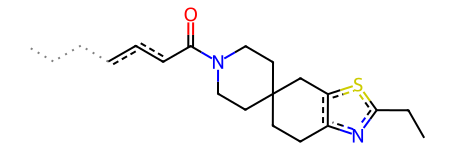

In [20]:
mcs_mol = Chem.MolFromSmarts(mcs_res.smartsString)
mcs_mol

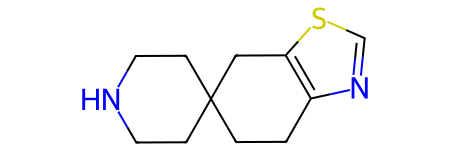

In [21]:
core_smi = "C1CC2(CCN1)CCc1ncsc1C2"
core_mol = Chem.MolFromSmiles(core_smi)
core_mol

,Mol,R1,R2,R3
0,,,,
1,,,,
2,,,,
3,,,,
4,,,,

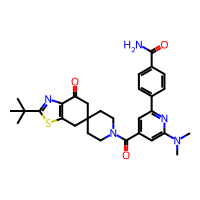
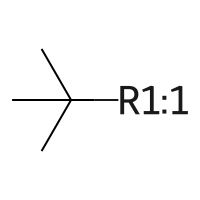
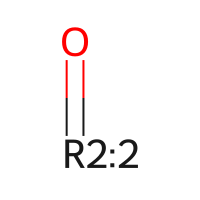
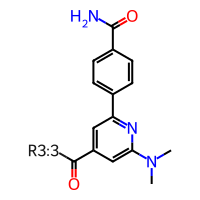
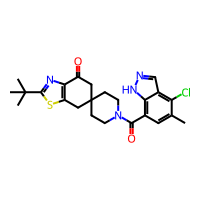
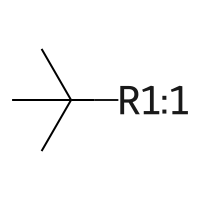
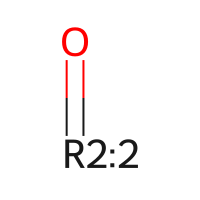
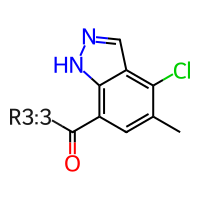
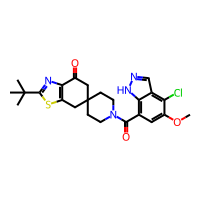
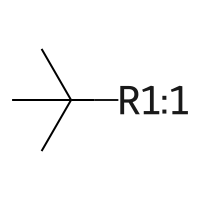
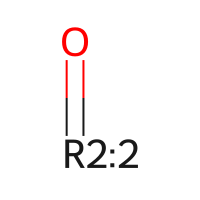
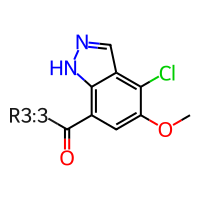
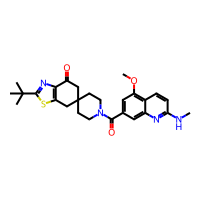
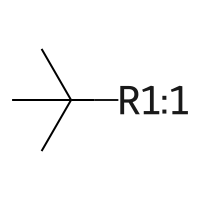
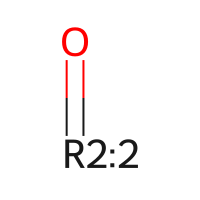
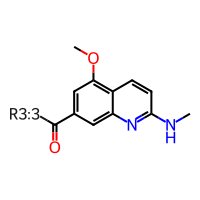
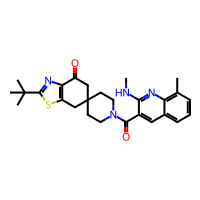
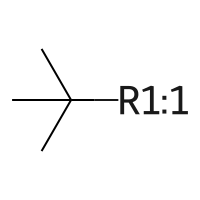
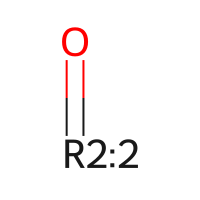
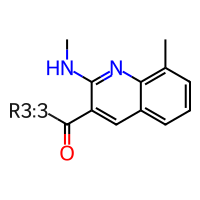

In [22]:
mols = df.ROMol
crgd,fails = rdRGroupDecomposition.RGroupDecompose([core_mol],mols,asRows=False)
PandasTools.RGroupDecompositionToFrame(crgd,[mols[i] for i in range(len(mols)) if i not in fails],).head()

In [23]:
mols = df.ROMol.values
rgd,fails = rdRGroupDecomposition.RGroupDecompose([core_mol],mols,asRows=True)

In [24]:
fails

[]

In [25]:
rgd[0]

{'Core': <rdkit.Chem.rdchem.Mol at 0x311b58f90>,
 'R1': <rdkit.Chem.rdchem.Mol at 0x311dc3ca0>,
 'R2': <rdkit.Chem.rdchem.Mol at 0x311dc3d80>,
 'R3': <rdkit.Chem.rdchem.Mol at 0x311dc3d10>}

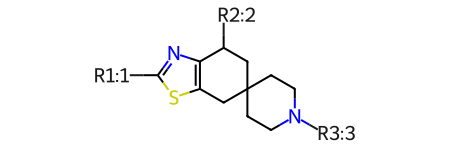

In [26]:
rgd[0]['Core']